In [6]:
import pandas as pd
import numpy as np

# Create a sample customer dataset
np.random.seed(42)

n = 200

df = pd.DataFrame({
    "CustomerID": range(1, n + 1),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Age": np.random.randint(18, 71, n),
    "Annual Income (k$)": np.random.randint(15, 138, n),
    "Spending Score (1-100)": np.random.randint(1, 101, n)
})

print("Sample customer dataset created successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Sample customer dataset created successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   49                 123                      78
1           2  Female   56                  65                      92
2           3    Male   66                  68                      69
3           4    Male   69                  22                      47
4           5    Male   49                  41                      94

Dataset shape: (200, 5)

Column names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   49                 123                      78
1           2  Female   56                  65                      92
2           3    Male   66                  68                      69
3           4    Male   69                  22                      47
4           5    Male   49                  41                      94

Dataset shape: (200, 5)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Spending category count:
Spending Category
High      71
Low       68
Medium    61
Name: count, dtype: int64

Dataset description:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   44.455000           75.585000               50.555000
std     5

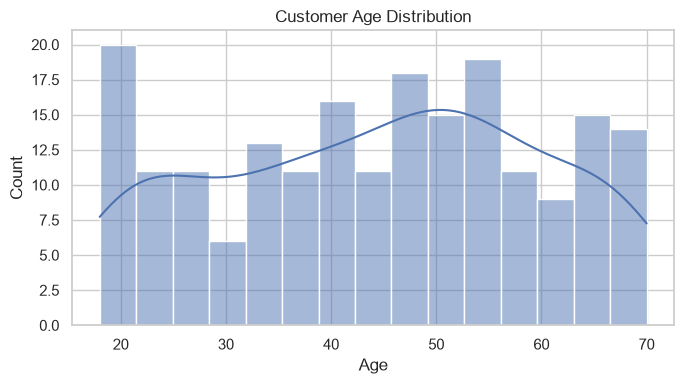

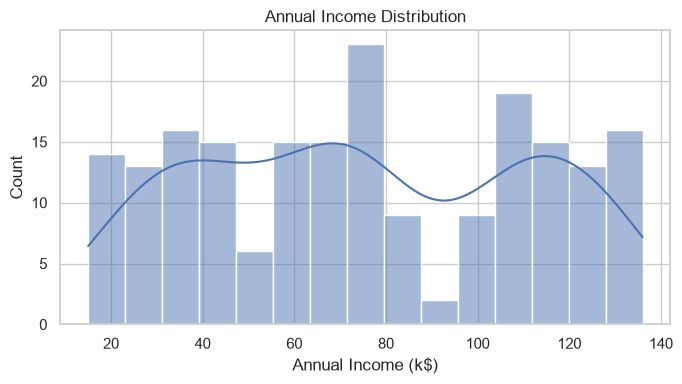

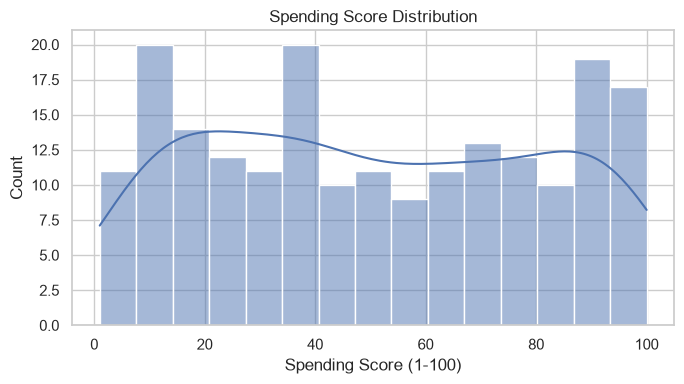

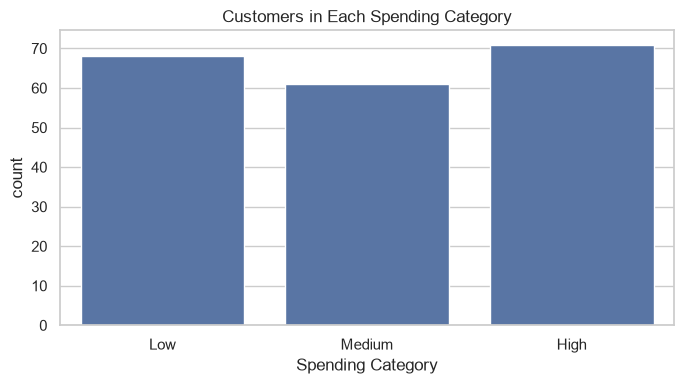

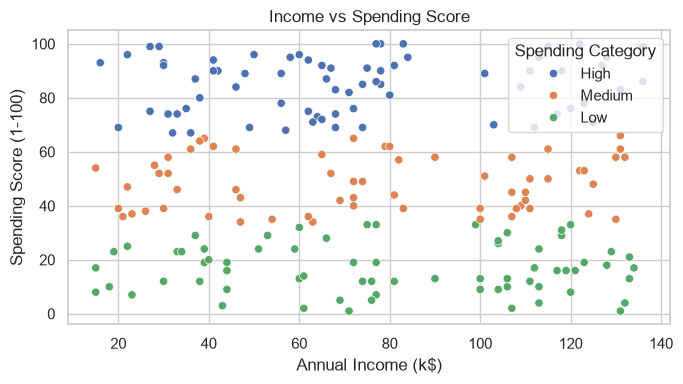


Model performance:
                     Accuracy  Precision  Recall  F1-score
Logistic Regression     0.275      0.258   0.275     0.257
Decision Tree           0.375      0.380   0.375     0.337


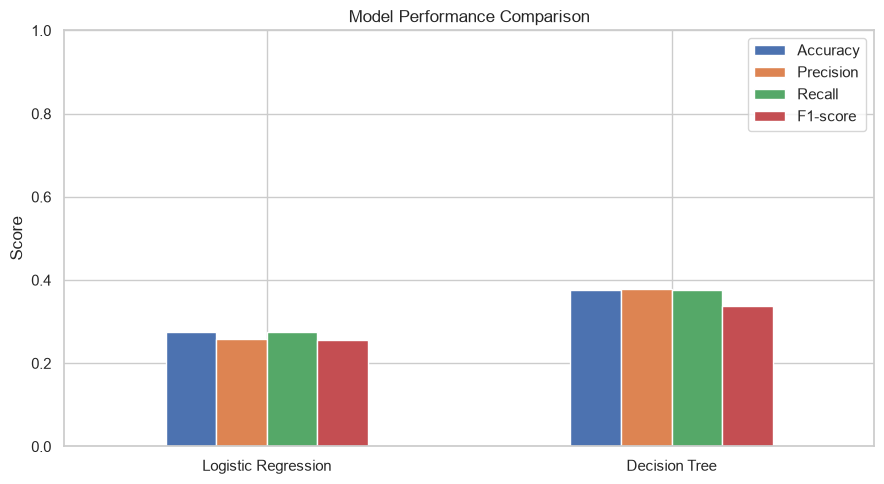


Selected model: Decision Tree

Classification report:
              precision    recall  f1-score   support

         Low       0.57      0.29      0.38        14
      Medium       0.17      0.08      0.11        12
        High       0.37      0.71      0.49        14

    accuracy                           0.38        40
   macro avg       0.37      0.36      0.33        40
weighted avg       0.38      0.38      0.34        40



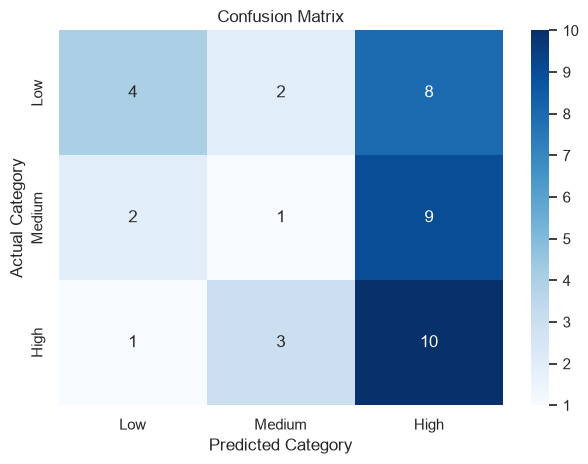


Feature importance / coefficient magnitude:
Age                   0.515
Annual Income (k$)    0.331
Gender_Male           0.153
dtype: float64


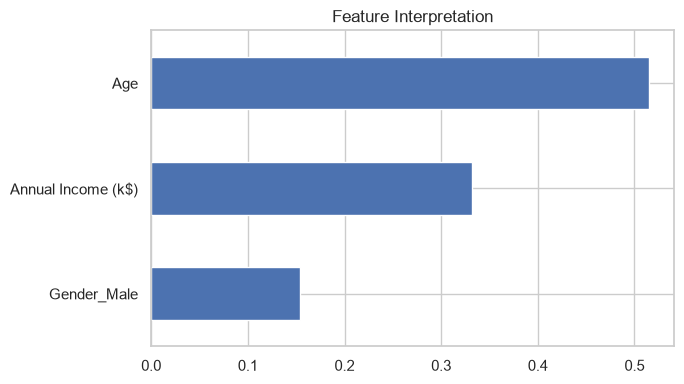


Predictions for new customers:
   Gender  Age  Annual Income (k$) Predicted Spending Category
0    Male   22                  25                         Low
1  Female   35                  65                        High
2  Female   50                 100                         Low

Project completed successfully!


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Creating a sample customer dataset
np.random.seed(42)

n = 200

df = pd.DataFrame({
    "CustomerID": range(1, n + 1),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Age": np.random.randint(18, 71, n),
    "Annual Income (k$)": np.random.randint(15, 138, n),
    "Spending Score (1-100)": np.random.randint(1, 101, n)
})

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Removing duplicate records
df.drop_duplicates(inplace=True)

# Creating spending categories
def get_category(score):
    if score <= 33:
        return "Low"
    elif score <= 66:
        return "Medium"
    else:
        return "High"

df["Spending Category"] = df["Spending Score (1-100)"].apply(get_category)

print("\nSpending category count:")
print(df["Spending Category"].value_counts())

# Basic statistical information
print("\nDataset description:")
print(df.describe())

# Visualization 1: Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Customer Age Distribution")
plt.tight_layout()
plt.show()

# Visualization 2: Annual income distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Annual Income (k$)", bins=15, kde=True)
plt.title("Annual Income Distribution")
plt.tight_layout()
plt.show()

# Visualization 3: Spending score distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Spending Score (1-100)", bins=15, kde=True)
plt.title("Spending Score Distribution")
plt.tight_layout()
plt.show()

# Visualization 4: Spending category count
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Spending Category",
              order=["Low", "Medium", "High"])
plt.title("Customers in Each Spending Category")
plt.tight_layout()
plt.show()

# Visualization 5: Income and spending score
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Spending Category"
)
plt.title("Income vs Spending Score")
plt.tight_layout()
plt.show()

# Preparing data for machine learning
# Spending Score is excluded because it creates the target category
X = df[["Gender", "Age", "Annual Income (k$)"]].copy()
X = pd.get_dummies(X, columns=["Gender"], drop_first=True, dtype=int)
y = df["Spending Category"]

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Training two models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model

    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    }

# Comparing model results
results_df = pd.DataFrame(results).T

print("\nModel performance:")
print(results_df.round(3))

results_df.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Selecting the model with the highest F1-score
best_name = results_df["F1-score"].idxmax()
best_model = trained_models[best_name]
predictions = best_model.predict(X_test)

print("\nSelected model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test, predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, predictions,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

# Checking which features influence the selected model
if best_name == "Decision Tree":
    importance = pd.Series(
        best_model.feature_importances_, index=X.columns
    )
else:
    importance = pd.Series(
        np.abs(best_model.named_steps["logisticregression"].coef_).mean(axis=0),
        index=X.columns
    )

print("\nFeature importance / coefficient magnitude:")
print(importance.sort_values(ascending=False).round(3))

importance.sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Feature Interpretation")
plt.tight_layout()
plt.show()

# Testing the model with new customer details
new_customers = pd.DataFrame({
    "Gender": ["Male", "Female", "Female"],
    "Age": [22, 35, 50],
    "Annual Income (k$)": [25, 65, 100]
})

new_X = pd.get_dummies(
    new_customers, columns=["Gender"], drop_first=True, dtype=int
)
new_X = new_X.reindex(columns=X.columns, fill_value=0)

new_customers["Predicted Spending Category"] = best_model.predict(new_X)

print("\nPredictions for new customers:")
print(new_customers)

print("\nProject completed successfully!")
